# 02 — Strand-awareness check on the TCAB1/WRAP53 stratifier

**The risk.** WRAP53 exon 1 carries a ~1,419 bp head-to-head antisense overlap with TP53.
On an unstranded library, reads falling in that interval cannot be assigned to the correct
gene, so WRAP53 TPM would be contaminated by TP53 — which would invalidate the Stage 1
stratifier outright.

**Why this may run after the freeze without compromising it.** WRAP53 expression is the
**exposure**, not an outcome, and prespec §4c committed the *decision rule* in advance.
This notebook only evaluates that rule. It reads no gene-effect values, and cell 2 below
asserts that structurally rather than trusting the author.

**Documentary finding (recorded as inconclusive).** The authoritative Broad pipeline
documentation and the 26Q1 release notes do not state strandedness. See §3. The empirical
diagnostics in §4 are therefore the deciding evidence, exactly as §4c anticipated.

## 1 — Header

In [1]:
import sys, random, time, warnings
from pathlib import Path

import numpy as np

random.seed(42)
np.random.seed(42)

_cwd = Path('.').resolve()
ROOT = _cwd if (_cwd / 'src').is_dir() else _cwd.parent
assert (ROOT / 'src').is_dir(), f"Cannot locate src/ -- tried {_cwd} and {_cwd.parent}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f'ROOT: {ROOT}')

warnings.filterwarnings('ignore', category=FutureWarning)

import pandas as pd
from src.utils import log_versions, run_timestamp, record_provenance, write_report, write_sha256_manifest

RUN_TIMESTAMP = run_timestamp()
VERSIONS = log_versions(['pandas', 'numpy', 'scipy', 'sklearn', 'matplotlib'])
print(f'Run: {RUN_TIMESTAMP}')
assert sys.version_info[:2] == (3, 12), f'Expected Python 3.12, got {sys.version_info[:2]}'
print(f'Python: {sys.version.split()[0]}')

ROOT: /Users/rinatrizvanov/Desktop/Projects/Project 1 - Comp Bio for Osteosarcoma/tcab1-bir-dependency


Library versions:
  pandas: 2.3.3
  numpy: 2.5.4
  scipy: 1.18.1
  sklearn: 1.9.1
  matplotlib: 3.11.2
Run: 2026-10-11T23:24:03Z
Python: 3.12.13


## 2 — Gate check: the outcome must be unreachable from here

`src/dependency_stats.py` is the only module that reads `CRISPRGeneEffect.csv`. If it is
not in `sys.modules` after importing everything this notebook needs, the outcome cannot
have been touched.

In [2]:
from src.strand_check import strand_decision, residualize_on_tp53, NULL_PERCENTILE_FLAG
from src.stratify import TCAB1_GENE, TP53_GENE, load_expression, osteosarcoma_rna_models
from src.plots import null_distribution_plot

leaked = [m for m in sys.modules if 'dependency_stats' in m]
assert not leaked, f'OUTCOME LEAK: {leaked} imported in notebook 02'
print('Gate check passed: src.dependency_stats is NOT loaded.')
print('CRISPRGeneEffect.csv is unreachable from this notebook.')

Gate check passed: src.dependency_stats is NOT loaded.
CRISPRGeneEffect.csv is unreachable from this notebook.


## 3 — Documentary check

Searched, in the order prespec §4c specifies:

| Source | Finding |
|---|---|
| Broad `depmap_omics/documentation/DepMap_processing_pipeline.md` | Expression generated by the **GTEx pipeline**: STAR alignment then **RSEM** quantification, STAR/RSEM indices built on **GENCODE v38** + GRCh38 with ERCC spike-ins. **Strandedness is not stated anywhere in the document.** |
| DepMap 26Q1 release announcement | No mention of the expression pipeline, quantifier, or strandedness. Only mutation-calling changes and new proteomics files. |
| `depmap_omics` per-quarter pipeline configs (`data/<quarter>/*.json`) | Not publicly reachable — the 25Q2 directory exposes only `omics_profile_to_sequencing_id.csv`. |
| Third-party data dictionaries | Describe the protein-coding TPM file as RSEM in **unstranded mode**, and the (now-removed) batch-corrected variant as RSEM "stranded or unstranded mode, **depending on each sample's sequencing protocol**" — implying a protocol mix across lines. Not authoritative. |
| DepMap 25Q2 release notes | STAR upgraded to 2.7.11b; quantification moved to **Salmon v1.10.0**. Bears on 26Q1's quantifier but not on library strandedness. |

**Conclusion: inconclusive, leaning unstranded.** No authoritative source states
strandedness, and the best available indication (third-party, non-authoritative) is
unstranded mode with a possible per-sample protocol mix. This is recorded as an
unresolved assumption, not as a finding. The §4c branch is decided by §4 below.

## 4 — Empirical diagnostics

Three measurements, per prespec §4c:

1. Spearman ρ(WRAP53, TP53) across all lines and within osteosarcoma lines.
2. The same ρ against a null of 1,000 **expression-matched** genes. Matching matters: ρ is
   attenuated for low-expressed noisy genes, so an unmatched null would be biased downward
   and make any correlation look anomalous.
3. Whether WRAP53 expression tracks WRAP53 **copy number** better than it tracks TP53
   expression. Copy number is strand-agnostic, so contamination predicts the reverse.

In [3]:
t0 = time.time()
diag, null_rhos = strand_decision()
print(f'({time.time() - t0:.0f}s)\n')
for line in diag.rationale:
    print(line)

(4s)

rho(WRAP53, TP53) across 1719 lines = +0.3539 (p = 6.89e-52)
rho(WRAP53, TP53) within 34 osteosarcoma lines = +0.2443 (p = 0.164)
Expression-matched null over 1000 genes: median +0.1344, p95 +0.3663, p99 +0.5007
Observed rho sits at the 94.40th percentile of that null
rho(WRAP53 expr, WRAP53 CN) in osteosarcoma lines = +0.5537 (p = 0.00083)
DIRECT: rho(WRAP53, TP53) is within what expression-matched gene pairs show (below the 99th percentile). No evidence of antisense cross-assignment. Use WRAP53 log2(TPM+1) directly as the Section 4 stratifier.


In [4]:
print(f'exceeds_null                 : {diag.exceeds_null}')
print(f'cn_tracks_better_than_tp53   : {diag.cn_tracks_better_than_tp53}')
print(f'\nBRANCH SELECTED              : {diag.branch}')

exceeds_null                 : False
cn_tracks_better_than_tp53   : True

BRANCH SELECTED              : direct


## 5 — Null distribution figure

wrote figures/strand_check_null.png


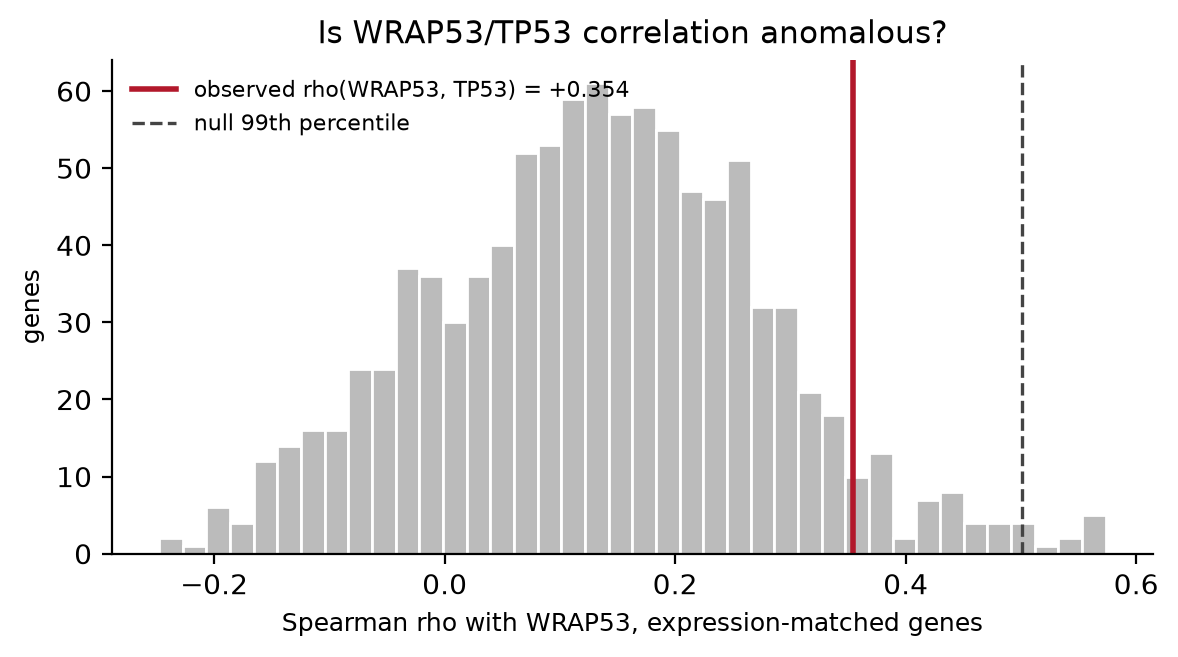

In [5]:
fig_path = null_distribution_plot(null_rhos, diag.rho_wrap53_tp53_all)
print(f'wrote {fig_path.relative_to(ROOT)}')
from IPython.display import Image, display
display(Image(filename=str(fig_path)))

## 6 — Stratifier consequences

Under the `direct` / `direct_cn_corroborated` branches the Section 4 stratifier is WRAP53
log2(TPM+1) as written. Under `fallback_cn_conjunction` it becomes the conjunction of low
expression and WRAP53 copy number, with the TP53-residualised split as sensitivity.

The residualised stratifier is computed here either way, so the notebook 04 sensitivity
analysis has it available and so the two can be compared against the §4c
"more than 3 of 16 lines disagree" threshold.

In [6]:
os_ids = osteosarcoma_rna_models()
pair_os = load_expression(os_ids, [TCAB1_GENE, TP53_GENE])
resid = residualize_on_tp53(pair_os)

comparison = pd.DataFrame({
    'WRAP53_log2tpm': pair_os[TCAB1_GENE],
    'TP53_log2tpm': pair_os[TP53_GENE],
    'WRAP53_resid_on_TP53': resid,
})
comparison['rank_direct'] = comparison['WRAP53_log2tpm'].rank()
comparison['rank_resid'] = comparison['WRAP53_resid_on_TP53'].rank()
comparison['rank_shift'] = (comparison['rank_direct'] - comparison['rank_resid']).abs()
print(f'osteosarcoma lines with RNA: {len(comparison)}')
print(f'Spearman(direct, residualised) rank agreement: '
      f'{comparison[["rank_direct","rank_resid"]].corr(method="spearman").iloc[0,1]:.4f}')
print(f'median |rank shift|: {comparison["rank_shift"].median():.1f}')
print()
print(comparison.sort_values('WRAP53_log2tpm').to_string())

osteosarcoma lines with RNA: 34
Spearman(direct, residualised) rank agreement: 0.9287
median |rank shift|: 3.0

            WRAP53_log2tpm  TP53_log2tpm  WRAP53_resid_on_TP53  rank_direct  rank_resid  rank_shift
ModelID                                                                                            
ACH-003185        0.000000      0.105981             -3.027332          1.5         1.0         0.5
ACH-002834        0.000000      0.000000             -3.009058          1.5         2.0         0.5
ACH-002142        2.041187      1.290525             -1.190402          3.0         6.0         3.0
ACH-001818        2.116691      4.603757             -1.686216          4.0         3.0         1.0
ACH-001712        2.476716      4.637402             -1.331992          5.0         5.0         0.0
ACH-001817        2.495810      5.079182             -1.389076          6.0         4.0         2.0
ACH-003171        2.748135      2.531331             -0.697413          7.0         9.0 

## 7 — Decision record and report

In [7]:
import json as _json
from src.utils import PROCESSED_DIR

decision = {
    'notebook': '02',
    'branch': diag.branch,
    'prespec_section': '4c',
    'documentary_finding': 'inconclusive_leaning_unstranded',
    'diagnostics': diag.as_dict(),
}
decision_path = PROCESSED_DIR / 'strand_decision.json'
decision_path.write_text(_json.dumps(decision, indent=2, sort_keys=True) + '\n')

strat_path = PROCESSED_DIR / 'wrap53_stratifier_candidates.csv'
comparison.to_csv(strat_path)
print(f'wrote {decision_path.name}')
print(f'wrote {strat_path.name}')

wrote strand_decision.json
wrote wrap53_stratifier_candidates.csv


In [8]:
BRANCH_MEANING = {
    'direct': 'Use WRAP53 log2(TPM+1) directly as the Section 4 stratifier.',
    'direct_cn_corroborated': ('Use WRAP53 log2(TPM+1) directly; report the copy-number '
                              'concordance alongside it.'),
    'fallback_cn_conjunction': ('Switch to the CN-conjunction stratifier; run the '
                               'TP53-residualised split as sensitivity.'),
}

lines = [
    '# Notebook 02 — Strand-awareness check on the TCAB1/WRAP53 stratifier',
    '',
    'Evaluates the branch rule committed in `docs/analytical_prespec.md` §4c. Reads no',
    'gene-effect values; the gate check asserts `src.dependency_stats` is not loaded.',
    '',
    '## Risk being tested',
    '',
    'WRAP53 exon 1 carries a ~1,419 bp head-to-head antisense overlap with TP53. On an',
    'unstranded library, reads there cannot be assigned to the correct gene, which would',
    'contaminate WRAP53 TPM with TP53 and invalidate the stratifier.',
    '',
    '## Documentary check: INCONCLUSIVE',
    '',
    '| Source | Finding |',
    '|---|---|',
    '| Broad `DepMap_processing_pipeline.md` | GTEx pipeline, STAR + RSEM, GENCODE v38 / GRCh38. Strandedness not stated. |',
    '| DepMap 26Q1 release announcement | No expression-pipeline or strandedness detail. |',
    '| `depmap_omics` per-quarter configs | Not publicly reachable. |',
    '| Third-party data dictionaries (non-authoritative) | RSEM "unstranded mode"; batch-corrected variant "stranded or unstranded depending on each sample\'s sequencing protocol". |',
    '| DepMap 25Q2 release notes | STAR 2.7.11b; quantification moved to Salmon v1.10.0. |',
    '',
    'No authoritative source states strandedness. Best available indication is unstranded,',
    'possibly mixed per sample. Recorded as an unresolved assumption, not a finding.',
    '',
    '## Empirical diagnostics',
    '',
]
lines += [f'- {r}' for r in diag.rationale[:5]]
lines += [
    '',
    '| Quantity | Value |',
    '|---|---|',
    f'| Lines (all) | {diag.n_all_lines} |',
    f'| Lines (osteosarcoma) | {diag.n_os_lines} |',
    f'| rho(WRAP53, TP53), all lines | {diag.rho_wrap53_tp53_all:+.4f} (p={diag.p_wrap53_tp53_all:.3g}) |',
    f'| rho(WRAP53, TP53), osteosarcoma | {diag.rho_wrap53_tp53_os:+.4f} (p={diag.p_wrap53_tp53_os:.3g}) |',
    f'| Expression-matched null genes | {diag.null_n_genes} |',
    f'| Null median / p95 / p99 | {diag.null_rho_median:+.4f} / {diag.null_rho_p95:+.4f} / {diag.null_rho_p99:+.4f} |',
    f'| Observed percentile in null | {diag.wrap53_percentile_in_null:.2f} |',
    f'| rho(WRAP53 expr, WRAP53 CN), osteosarcoma | {diag.rho_wrap53_expr_vs_cn_os:+.4f} (p={diag.p_wrap53_expr_vs_cn_os:.3g}) |',
    f'| Exceeds null {NULL_PERCENTILE_FLAG:.0f}th percentile | {diag.exceeds_null} |',
    f'| CN tracks better than TP53 | {diag.cn_tracks_better_than_tp53} |',
    '',
    '## Branch selected',
    '',
    f'**`{diag.branch}`**',
    '',
    BRANCH_MEANING[diag.branch],
    '',
    diag.rationale[-1],
    '',
    '## Stratifier candidates',
    '',
    f'Direct and TP53-residualised WRAP53 computed for all {len(comparison)} osteosarcoma',
    'lines with RNA, written to `wrap53_stratifier_candidates.csv`. Rank agreement between',
    'the two (Spearman): '
    f'{comparison[["rank_direct","rank_resid"]].corr(method="spearman").iloc[0,1]:.4f}.',
    '',
    '## Figure',
    '',
    '`figures/strand_check_null.png` — observed rho against the expression-matched null.',
]
report = write_report('02', lines)
manifest = write_sha256_manifest('02', [report, decision_path, strat_path])
record_provenance([{
    'notebook': '02', 'run_timestamp': RUN_TIMESTAMP, 'branch': diag.branch,
    'rho_wrap53_tp53_all': diag.rho_wrap53_tp53_all,
    'percentile_in_null': diag.wrap53_percentile_in_null,
}])
print(f'wrote {report.name}')
print(f'wrote {manifest.name}')
print(f'\nBRANCH: {diag.branch}')

wrote notebook_02_report.md
wrote notebook_02_sha256.json

BRANCH: direct
